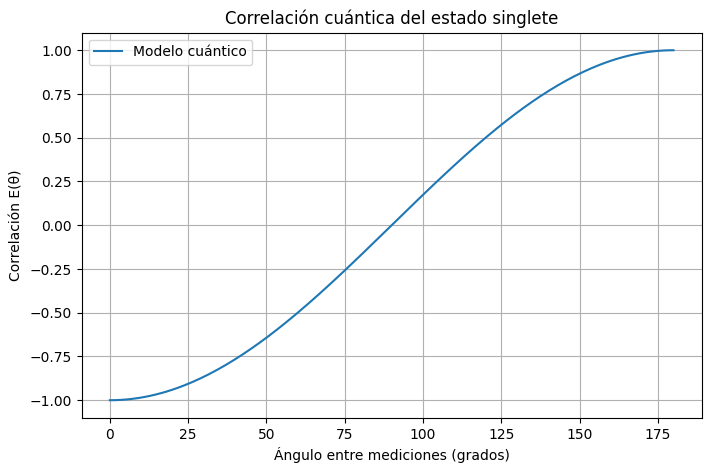

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

# Ángulos de medición entre 0° y 180°
theta = np.linspace(0, np.pi, 200)

# Correlación cuántica del estado singlete
E = -np.cos(theta)

plt.figure(figsize=(8, 5))
plt.plot(np.degrees(theta), E, label="Modelo cuántico")

plt.xlabel("Ángulo entre mediciones (grados)")
plt.ylabel("Correlación E(θ)")
plt.title("Correlación cuántica del estado singlete")
plt.grid(True)
plt.legend()
plt.show()


Correlación simulada: -1.0
Primeros 10 resultados de Alicia: [-1  1  1 -1 -1  1 -1  1 -1 -1]
Primeros 10 resultados de Bob:    [ 1 -1 -1  1  1 -1  1 -1  1  1]


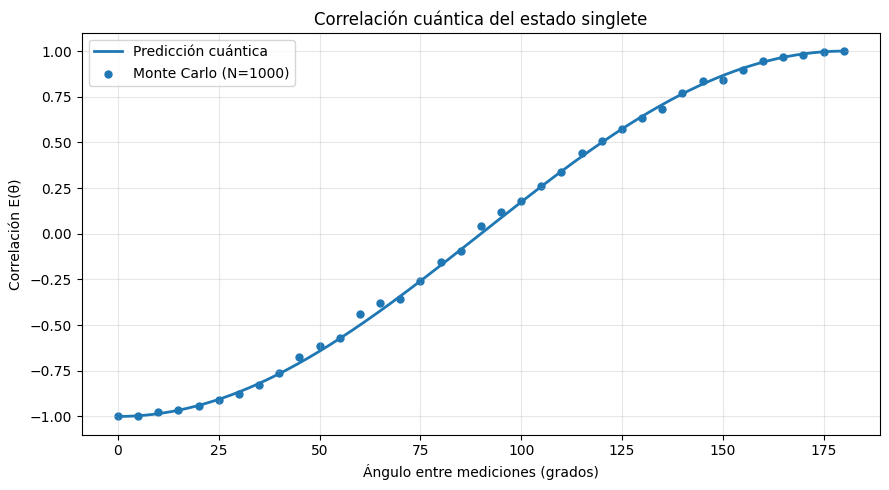

Correlación teórica: -0.7071

N =   100 | E = -0.7200 | Error absoluto = 0.0129
N =  1000 | E = -0.7280 | Error absoluto = 0.0209
N = 10000 | E = -0.7070 | Error absoluto = 0.0001


In [ ]:

import numpy as np
import matplotlib.pyplot as plt

# Generador de números aleatorios reproducible
rng = np.random.default_rng(42)

# Número de pares de partículas por ángulo
N = 1000

def simular_correlacion(theta, N, rng):
    # Resultado de Alicia: +1 o -1
    A = rng.choice([-1, 1], size=N)

    # Probabilidad de que Bob obtenga
    # el resultado opuesto al de Alicia
    p_opuesto = (1 + np.cos(theta)) / 2

    # Decidir si los resultados son opuestos
    opuestos = rng.random(N) < p_opuesto

    # Construir los resultados de Bob
    B = np.where(opuestos, -A, A)

    # Correlación estimada
    E = np.mean(A * B)

    return E, A, B

theta = np.deg2rad(0)

E, A, B = simular_correlacion(theta, N, rng)

print("Correlación simulada:", E)
print("Primeros 10 resultados de Alicia:", A[:10])
print("Primeros 10 resultados de Bob:   ", B[:10])

angulos = np.linspace(0, 180, 37)
correlaciones = []

for angulo in angulos:
    theta = np.deg2rad(angulo)

    E, _, _ = simular_correlacion(theta, N, rng)
    correlaciones.append(E)

correlaciones = np.array(correlaciones)

# Curva cuántica teórica
angulos_teoria = np.linspace(0, 180, 500)
E_teoria = -np.cos(np.deg2rad(angulos_teoria))

plt.figure(figsize=(9, 5))

plt.plot(
    angulos_teoria,
    E_teoria,
    label="Predicción cuántica",
    linewidth=2
)

plt.scatter(
    angulos,
    correlaciones,
    label=f"Monte Carlo (N={N})",
    s=25
)

plt.xlabel("Ángulo entre mediciones (grados)")
plt.ylabel("Correlación E(θ)")
plt.title("Correlación cuántica del estado singlete")
plt.ylim(-1.1, 1.1)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

theta = np.deg2rad(45)
E_teorica = -np.cos(theta)

print(f"Correlación teórica: {E_teorica:.4f}")
print()

for N_prueba in [100, 1000, 10000]:
    E, _, _ = simular_correlacion(
        theta, N_prueba, rng
    )

    error = abs(E - E_teorica)

    print(
        f"N = {N_prueba:5d} | "
        f"E = {E:.4f} | "
        f"Error absoluto = {error:.4f}"
    )


E(a,b)   = -0.7136
E(a,b')  = 0.7124
E(a',b)  = -0.7088
E(a',b') = -0.7158

S simulado = -2.8506
|S| = 2.8506
Límite clásico CHSH = 2
Máximo cuántico = 2.8284
N =    100  |S| = 3.1000
N =   1000  |S| = 2.8420
N =  10000  |S| = 2.8258
N = 100000  |S| = 2.8239

Valor teórico: 2.8284


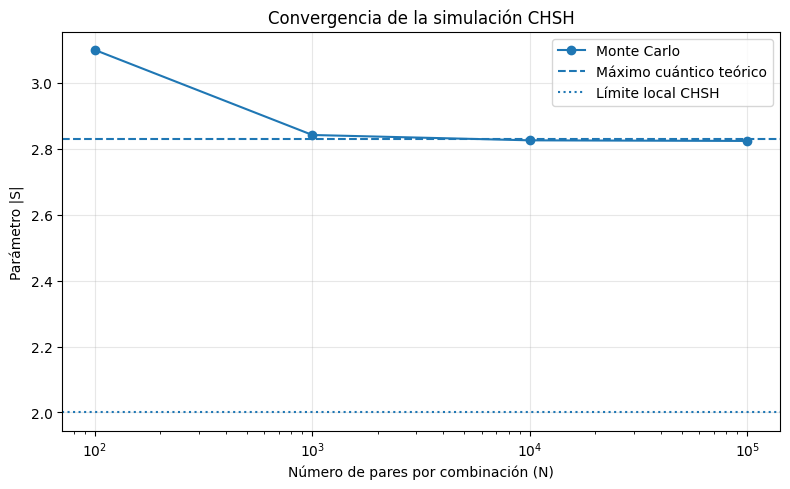

In [ ]:
## 2. Simulación de la desigualdad CHSH
# Orientaciones de los aparatos, en grados
a = 0
a_prima = 90
b = 45
b_prima = 135

# Número de pares de partículas simulados por combinación
N_chsh = 10000

# Calculamos las cuatro correlaciones
E_ab, _, _ = simular_correlacion(
    np.radians(a - b), N_chsh, rng
)

E_ab_prima, _, _ = simular_correlacion(
    np.radians(a - b_prima), N_chsh, rng
)

E_a_prima_b, _, _ = simular_correlacion(
    np.radians(a_prima - b), N_chsh, rng
)

E_a_prima_b_prima, _, _ = simular_correlacion(
    np.radians(a_prima - b_prima), N_chsh, rng
)

# Parámetro CHSH
S = E_ab - E_ab_prima + E_a_prima_b + E_a_prima_b_prima

print(f"E(a,b)   = {E_ab:.4f}")
print(f"E(a,b')  = {E_ab_prima:.4f}")
print(f"E(a',b)  = {E_a_prima_b:.4f}")
print(f"E(a',b') = {E_a_prima_b_prima:.4f}")

print(f"\nS simulado = {S:.4f}")
print(f"|S| = {abs(S):.4f}")
print(f"Límite clásico CHSH = 2")
print(f"Máximo cuántico = {2*np.sqrt(2):.4f}")

# Diferentes cantidades de pares por combinación
valores_N = [100, 1000, 10000, 100000]

S_resultados = []

for N_actual in valores_N:

    E1, _, _ = simular_correlacion(np.radians(a - b), N_actual, rng)
    E2, _, _ = simular_correlacion(np.radians(a - b_prima), N_actual, rng)
    E3, _, _ = simular_correlacion(np.radians(a_prima - b), N_actual, rng)
    E4, _, _ = simular_correlacion(np.radians(a_prima - b_prima), N_actual, rng)

    S_actual = E1 - E2 + E3 + E4
    S_resultados.append(abs(S_actual))

    print(f"N = {N_actual:6d}  |S| = {abs(S_actual):.4f}")

print(f"\nValor teórico: {2*np.sqrt(2):.4f}")

plt.figure(figsize=(8, 5))

# Resultados obtenidos en la simulación
plt.plot(valores_N, S_resultados, 'o-',
         label='Monte Carlo')

# Predicción cuántica ideal
plt.axhline(2*np.sqrt(2), linestyle='--',
            label='Máximo cuántico teórico')

# Límite de variables ocultas locales
plt.axhline(2, linestyle=':',
            label='Límite local CHSH')

plt.xscale('log')

plt.xlabel('Número de pares por combinación (N)')
plt.ylabel('Parámetro |S|')
plt.title('Convergencia de la simulación CHSH')

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig('convergencia_CHSH.png', dpi=300)
plt.show()

SEMILLA: 42
PARES POR CONFIGURACIÓN: 100000

Modelo: cuantico
Correlaciones: [-0.70538  0.70814 -0.7098  -0.70824]
S = -2.83156
|S| = 2.83156

Modelo: local
Correlaciones: [-0.50166  0.4997  -0.4976  -0.4995 ]
S = -1.99846
|S| = 1.99846


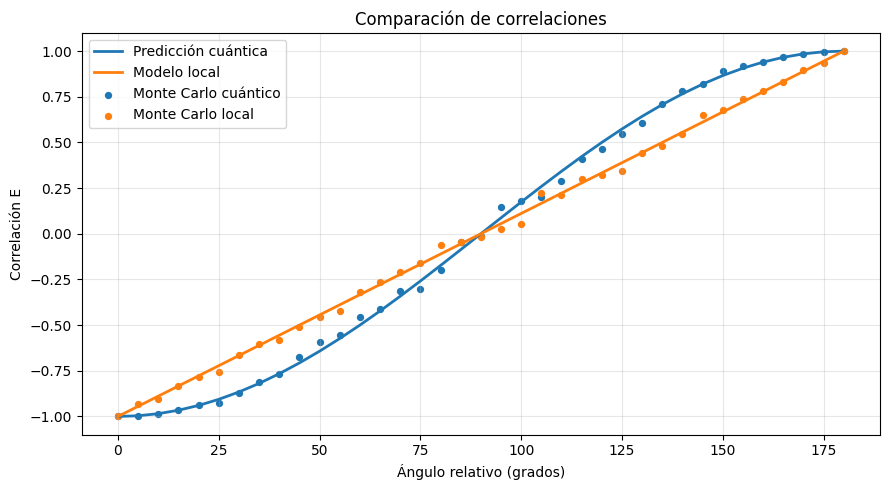


RESULTADOS DE RUIDO
V=1.00 | |S|=2.82692 | Teórico=2.82843
V=0.95 | |S|=2.68452 | Teórico=2.68701
V=0.90 | |S|=2.54540 | Teórico=2.54558
V=0.85 | |S|=2.40876 | Teórico=2.40416
V=0.80 | |S|=2.25900 | Teórico=2.26274
V=0.75 | |S|=2.12102 | Teórico=2.12132
V=0.70 | |S|=1.98522 | Teórico=1.97990
V=0.60 | |S|=1.69460 | Teórico=1.69706
V=0.50 | |S|=1.41644 | Teórico=1.41421


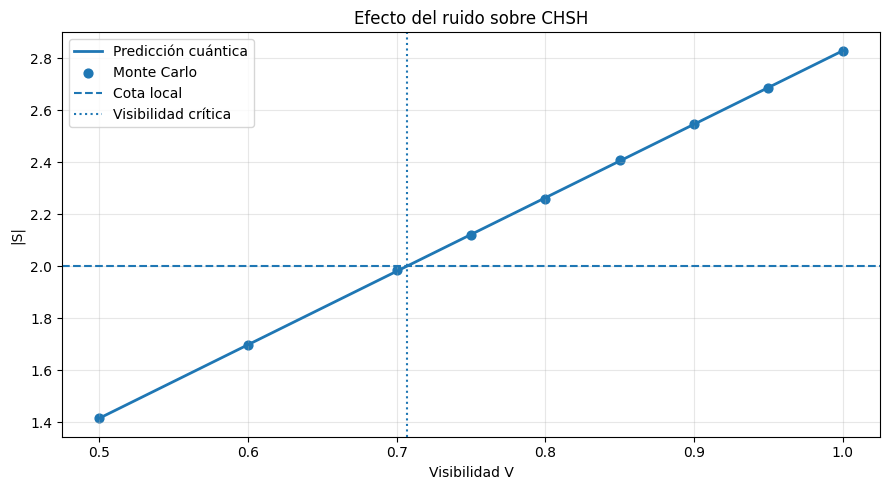


EFICIENCIA DE DETECCIÓN
eta=1.00 | Coincidencias=[np.int64(100000), np.int64(100000), np.int64(100000), np.int64(100000)] | |S|=2.83002
eta=0.90 | Coincidencias=[np.int64(81086), np.int64(81022), np.int64(81042), np.int64(80987)] | |S|=2.83173
eta=0.80 | Coincidencias=[np.int64(63930), np.int64(64258), np.int64(64062), np.int64(64049)] | |S|=2.82123
eta=0.70 | Coincidencias=[np.int64(49011), np.int64(48994), np.int64(49034), np.int64(49086)] | |S|=2.82761
eta=0.60 | Coincidencias=[np.int64(35974), np.int64(35864), np.int64(35951), np.int64(35664)] | |S|=2.82421
eta=0.50 | Coincidencias=[np.int64(25037), np.int64(25002), np.int64(24880), np.int64(25121)] | |S|=2.82438

SIMULACIÓN FINALIZADA


In [ ]:

import numpy as np
import matplotlib.pyplot as plt

# ==================================================
# SIMULACIÓN DE BELL Y DESIGUALDAD CHSH
# ==================================================

SEED = 42
N = 100_000
rng = np.random.default_rng(SEED)

# Direcciones de medición en grados
ANGULOS = {
    "a": 0.0,
    "ap": 90.0,
    "b": 45.0,
    "bp": 135.0
}

PARES = [
    ("a", "b"),
    ("a", "bp"),
    ("ap", "b"),
    ("ap", "bp")
]

def angulo_relativo(x, y):
    return np.deg2rad(ANGULOS[x] - ANGULOS[y])


# ==================================================
# 1. MODELO CUÁNTICO
# ==================================================

def muestra_cuantica(theta, n, V=1.0):
    A = rng.choice([-1, 1], size=n)

    p_opuestos = (1 + V * np.cos(theta)) / 2

    opuestos = rng.random(n) < p_opuestos

    B = np.where(opuestos, -A, A)

    return A, B


# ==================================================
# 2. MODELO DE VARIABLES OCULTAS LOCALES
# ==================================================

def muestra_local(angulo_a, angulo_b, n):
    lam = rng.uniform(0, 2*np.pi, size=n)

    A = np.where(
        np.cos(lam - angulo_a) >= 0, 1, -1
    )

    B = -np.where(
        np.cos(lam - angulo_b) >= 0, 1, -1
    )

    return A, B


# ==================================================
# 3. CÁLCULO DE CHSH
# ==================================================

def calcular_chsh(c):
    return c[0] - c[1] + c[2] + c[3]


def simular_chsh(n, V=1.0, modelo="cuantico"):
    correlaciones = []

    for x, y in PARES:

        if modelo == "cuantico":
            A, B = muestra_cuantica(
                angulo_relativo(x, y), n, V
            )

        elif modelo == "local":
            A, B = muestra_local(
                np.deg2rad(ANGULOS[x]),
                np.deg2rad(ANGULOS[y]),
                n
            )

        correlaciones.append(np.mean(A * B))

    S = calcular_chsh(correlaciones)

    return np.array(correlaciones), S


print("SEMILLA:", SEED)
print("PARES POR CONFIGURACIÓN:", N)

for modelo in ["cuantico", "local"]:

    c, S = simular_chsh(N, modelo=modelo)

    print("\nModelo:", modelo)
    print("Correlaciones:", np.round(c, 5))
    print("S =", round(S, 5))
    print("|S| =", round(abs(S), 5))


# ==================================================
# 4. GRÁFICA: MODELO CUÁNTICO VS. LOCAL
# ==================================================

angulos = np.linspace(0, np.pi, 37)

E_cuantica = -np.cos(angulos)
E_local = -1 + 2*angulos/np.pi

sim_cuantica = []
sim_local = []

for theta in angulos:

    A, B = muestra_cuantica(theta, 1000)
    sim_cuantica.append(np.mean(A * B))

    A, B = muestra_local(0, theta, 1000)
    sim_local.append(np.mean(A * B))


plt.figure(figsize=(9, 5))

plt.plot(
    np.rad2deg(angulos),
    E_cuantica,
    label="Predicción cuántica",
    linewidth=2
)

plt.plot(
    np.rad2deg(angulos),
    E_local,
    label="Modelo local",
    linewidth=2
)

plt.scatter(
    np.rad2deg(angulos),
    sim_cuantica,
    label="Monte Carlo cuántico",
    s=18
)

plt.scatter(
    np.rad2deg(angulos),
    sim_local,
    label="Monte Carlo local",
    s=18
)

plt.xlabel("Ángulo relativo (grados)")
plt.ylabel("Correlación E")
plt.title("Comparación de correlaciones")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    "comparacion_local_cuantica.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ==================================================
# 5. RUIDO Y VISIBILIDAD
# ==================================================

visibilidades = np.array([
    1.00, 0.95, 0.90, 0.85,
    0.80, 0.75, 0.70, 0.60, 0.50
])

resultados_ruido = []

print("\nRESULTADOS DE RUIDO")

for V in visibilidades:

    c, S = simular_chsh(N, V=V)

    resultados_ruido.append(abs(S))

    print(
        f"V={V:.2f} | "
        f"|S|={abs(S):.5f} | "
        f"Teórico={2*np.sqrt(2)*V:.5f}"
    )


V_continuo = np.linspace(0.5, 1.0, 200)

plt.figure(figsize=(9, 5))

plt.plot(
    V_continuo,
    2*np.sqrt(2)*V_continuo,
    label="Predicción cuántica",
    linewidth=2
)

plt.scatter(
    visibilidades,
    resultados_ruido,
    label="Monte Carlo",
    s=40
)

plt.axhline(
    2,
    linestyle="--",
    label="Cota local"
)

plt.axvline(
    1/np.sqrt(2),
    linestyle=":",
    label="Visibilidad crítica"
)

plt.xlabel("Visibilidad V")
plt.ylabel("|S|")
plt.title("Efecto del ruido sobre CHSH")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "ruido_visibilidad_CHSH.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ==================================================
# 6. EFICIENCIA DE DETECCIÓN
# ==================================================

eficiencias = [1.0, 0.9, 0.8, 0.7, 0.6, 0.5]

print("\nEFICIENCIA DE DETECCIÓN")

for eta in eficiencias:

    correlaciones = []
    coincidencias = []

    for x, y in PARES:

        A, B = muestra_cuantica(
            angulo_relativo(x, y), N
        )

        # Pérdidas independientes en cada detector
        detecta_A = rng.random(N) < eta
        detecta_B = rng.random(N) < eta

        conservar = detecta_A & detecta_B

        coincidencias.append(
            np.sum(conservar)
        )

        if np.any(conservar):
            E = np.mean(
                (A * B)[conservar]
            )
        else:
            E = np.nan

        correlaciones.append(E)

    S = calcular_chsh(correlaciones)

    print(
        f"eta={eta:.2f} | "
        f"Coincidencias={coincidencias} | "
        f"|S|={abs(S):.5f}"
    )

print("\nSIMULACIÓN FINALIZADA")



## Reproducción de la Figura 4a de Hensen et al. (2015)

Se reproducen las cuatro correlaciones CHSH de la Figura 4a utilizando los conteos experimentales publicados por Hensen et al. (2015).

El código calcula las correlaciones, sus incertidumbres estadísticas y el parámetro CHSH, y genera una representación gráfica de los resultados.

**Fuente:** Hensen et al., *Nature* 526, 682–686 (2015).
https://doi.org/10.1038/nature15759



,Configuración,N positivos,N negativos,Total,Correlación E,Error estadístico
0,"(0,0)",46,7,53,0.7358,0.0930
1,"(0,1)",63,16,79,0.5949,0.0904
2,"(1,0)",46,16,62,0.4839,0.1111
3,"(1,1)",10,41,51,-0.6078,0.1112



Total de eventos: 245
Parámetro CHSH: S = 2.4225
Incertidumbre aproximada: 0.2038
Resultado publicado: S = 2.42 ± 0.20


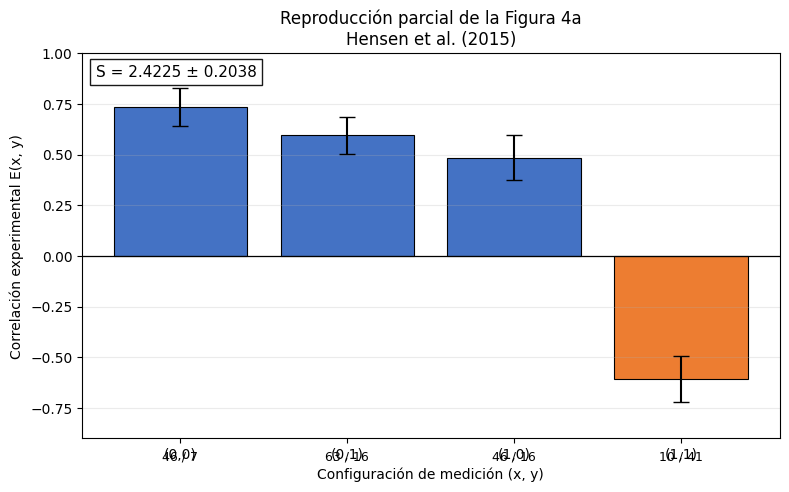


Figura guardada en: figuras/reproduccion_hensen_fig4a.png


In [1]:

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

# Datos experimentales de Hensen et al. (2015)
# Figura 4a: conteos para las cuatro configuraciones
configuraciones = ["(0,0)", "(0,1)", "(1,0)", "(1,1)"]

N_positivos = np.array([46, 63, 46, 10])
N_negativos = np.array([7, 16, 16, 41])

# Número total de eventos por configuración
N = N_positivos + N_negativos

# Correlaciones experimentales
E = (N_positivos - N_negativos) / N

# Incertidumbres estadísticas
sigma_E = np.sqrt((1 - E**2) / N)

# Parámetro CHSH
S = E[0] + E[1] + E[2] - E[3]

# Incertidumbre combinada aproximada
sigma_S = np.sqrt(np.sum(sigma_E**2))

# Tabla de resultados
tabla = pd.DataFrame({
    "Configuración": configuraciones,
    "N positivos": N_positivos,
    "N negativos": N_negativos,
    "Total": N,
    "Correlación E": E,
    "Error estadístico": sigma_E
})

display(tabla.round(4))

print(f"\nTotal de eventos: {np.sum(N)}")
print(f"Parámetro CHSH: S = {S:.4f}")
print(f"Incertidumbre aproximada: {sigma_S:.4f}")
print("Resultado publicado: S = 2.42 ± 0.20")

# Reproducción gráfica
fig, ax = plt.subplots(figsize=(9, 5.5))

x = np.arange(len(configuraciones))

ax.bar(
    x, E,
    yerr=sigma_E,
    capsize=6,
    color=["#4472C4", "#4472C4", "#4472C4", "#ED7D31"],
    edgecolor="black",
    linewidth=0.8,
    error_kw={"elinewidth": 1.5}
)

ax.axhline(0, color="black", linewidth=0.9)

ax.set_xticks(x)
ax.set_xticklabels(configuraciones)
ax.set_xlabel("Configuración de medición (x, y)")
ax.set_ylabel("Correlación experimental E(x, y)")
ax.set_title(
    "Reproducción parcial de la Figura 4a\n"
    "Hensen et al. (2015)"
)

ax.set_ylim(-0.9, 1.0)
ax.grid(axis="y", alpha=0.25)

# Etiquetas de los conteos
for i, (pos, neg) in enumerate(
    zip(N_positivos, N_negativos)
):
    ax.text(
        i, -0.96,
        f"{pos} / {neg}",
        ha="center",
        va="top",
        fontsize=9,
        clip_on=False
    )

ax.text(
    0.02, 0.97,
    f"S = {S:.4f} ± {sigma_S:.4f}",
    transform=ax.transAxes,
    ha="left",
    va="top",
    fontsize=11,
    bbox=dict(facecolor="white", alpha=0.9)
)

fig.subplots_adjust(bottom=0.18)
plt.show()

# Guardar la figura
carpeta = Path("figuras")
carpeta.mkdir(exist_ok=True)

ruta = carpeta / "reproduccion_hensen_fig4a.png"
fig.savefig(ruta, dpi=300, bbox_inches="tight")

print(f"\nFigura guardada en: {ruta}")



### Resultado

La reproducción permite recuperar el valor experimental $S\approx 2.42$, consistente con el resultado publicado. La gráfica reconstruye las correlaciones a partir de los conteos originales; no constituye una nueva medición experimental.
